# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

# Linear Regression

# Used Car Price Prediction

* **Goal:** predict the advertised price of a used Ford car from its model, year, transmission, mileage, fuel type, tax, fuel economy, and engine size.
- **Required data:** place the original `ford.csv` beside this notebook, or change `DATA_PATH` in the configuration cell; the full CSV is not embedded in the uploaded notebook.
- **Environment:** use Python 3 with pandas, NumPy, Matplotlib, seaborn, SciPy, scikit-learn 1.2 or newer, and IPython; Jupyter and Colab normally provide IPython.
- **Setup if needed:** run `%pip install pandas numpy matplotlib seaborn scipy "scikit-learn>=1.2"` in a separate setup cell, then restart the kernel.
- **Run order:** execute the cells from top to bottom after supplying the CSV; Google Drive mounting and changing the working directory are no longer required.
- **Units:** price and tax are kept in the source CSV's currency units; confirm the dataset documentation before labeling them as pounds or another currency, and confirm the mileage, mpg, and engine-size conventions.
- **Validation status:** the revised code was tested using separate synthetic test data; original-data scores could not be recomputed without `ford.csv`, so stale outputs have been cleared.


### 1. Import the libraries

- Use pandas and NumPy for data handling, Matplotlib and seaborn for plots, and SciPy for a residual Q–Q plot.
- Use a scikit-learn pipeline so imputation, scaling, and encoding are fitted only on the relevant training data.
- Set a readable plotting style without relying on a version-specific seaborn style name.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})


### 2. Configure paths and reproducibility

- Change only `DATA_PATH` to point to your own CSV; a Colab Drive path is also accepted after you mount Drive yourself if needed.
- Keep the original 70% training / 30% test split and a fixed random seed.
- Set a configurable plausible year range; the default rejects values such as the original saved maximum year of 2060 without guessing its intended value.
- Treat engine size zero as missing by default; switch this off only if the dataset documentation establishes that zero is meaningful, such as for an electric vehicle.


In [2]:
DATA_PATH = Path("ford.csv")
RANDOM_STATE = 42
TEST_SIZE = 0.30
CV_FOLDS = 5
MIN_MODEL_YEAR = 1900
MAX_MODEL_YEAR = pd.Timestamp.today().year + 1
ZERO_ENGINE_SIZE_IS_MISSING = True

numeric_features = ["year", "mileage", "tax", "mpg", "engineSize"]
categorical_features = ["model", "transmission", "fuelType"]
feature_columns = numeric_features + categorical_features
target_column = "price"
required_columns = feature_columns + [target_column]


### 3. Load and preview the source data

- Read the CSV without changing the current working directory, and preserve the unmodified table as `raw_df`.
- Stop with an actionable message if the data file is absent; the saved first five rows cannot reconstruct the original 17,965 records.
- Preview the original columns before cleaning.


In [3]:
data_path = Path(DATA_PATH).expanduser()
if not data_path.is_file():
    raise FileNotFoundError(
        f"Cannot find {data_path.resolve()}. Place ford.csv beside this notebook "
        "or set DATA_PATH to the correct CSV path."
    )
raw_df = pd.read_csv(data_path)
print(f"Loaded {len(raw_df):,} rows and {raw_df.shape[1]} columns.")
display(raw_df.head())


Loaded 17,965 rows and 9 columns.


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


### 4. Inspect column types and missing values

- Check the original data types, nonmissing counts, and column names.
- Display missing counts rather than assuming that the new CSV matches the original saved output.
- Keep this inspection separate from model fitting.


In [4]:
raw_df.info()
display(raw_df.isna().sum().to_frame("Original missing values"))
print("Original columns:", raw_df.columns.tolist())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17965 entries, 0 to 17964
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17965 non-null  object 
 1   year          17965 non-null  int64  
 2   price         17965 non-null  int64  
 3   transmission  17965 non-null  object 
 4   mileage       17965 non-null  int64  
 5   fuelType      17965 non-null  object 
 6   tax           17965 non-null  int64  
 7   mpg           17965 non-null  float64
 8   engineSize    17965 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 1.2+ MB


,Original missing values
model,0
year,0
price,0
transmission,0
mileage,0
fuelType,0
tax,0
mpg,0
engineSize,0


Original columns: ['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax', 'mpg', 'engineSize']


### 5. Validate the schema and normalize text

- Remove whitespace from column names and category labels, including the leading spaces commonly present in car model names.
- Keep model, transmission, and fuel type as nominal categories instead of replacing them with arbitrary integers.
- Represent blank categories as missing values and convert numeric columns explicitly; report nonnumeric entries rather than silently accepting them.


In [5]:
df = raw_df.copy()
df.columns = df.columns.str.strip()
if df.columns.duplicated().any():
    raise ValueError("Duplicate column names after whitespace normalization.")
missing_columns = set(required_columns).difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")
df = df[required_columns].copy()

for column in categorical_features:
    df[column] = df[column].map(lambda value: value.strip() if isinstance(value, str) else value)
    df[column] = df[column].replace(r"^\s*$", np.nan, regex=True)

invalid_numeric = {}
for column in numeric_features + [target_column]:
    parsed = pd.to_numeric(df[column], errors="coerce")
    invalid_numeric[column] = int((df[column].notna() & parsed.isna()).sum())
    df[column] = parsed.replace([np.inf, -np.inf], np.nan).astype(float)
display(pd.Series(invalid_numeric, name="Nonnumeric values converted to missing").to_frame())


,Nonnumeric values converted to missing
year,0
mileage,0
tax,0
mpg,0
engineSize,0
price,0


### 6. Handle invalid values and repeated records

- Remove rows with missing or nonpositive prices because a missing target must not be imputed.
- Convert implausible years, negative mileage or tax, nonpositive mpg, and invalid engine sizes to missing; learn imputation values later from training data only.
- Keep an audit table with the number of affected values; do not replace 2060 with an invented year.
- Remove exact repeated records before splitting to reduce duplicate leakage; identical specifications can also represent different real cars, so review this policy if unique listing identifiers become available.
- Retain unusual but valid prices and mileage values rather than deleting outliers using test-set statistics.


In [6]:
audit = []
bad_target = df[target_column].isna() | df[target_column].le(0)
audit.append({"Action": "Remove missing/nonpositive target", "Count": int(bad_target.sum())})
df = df.loc[~bad_target].copy()

invalid_masks = {
    "year": df["year"].notna() & (
        ~df["year"].between(MIN_MODEL_YEAR, MAX_MODEL_YEAR)
        | df["year"].mod(1).ne(0)
    ),
    "mileage": df["mileage"].lt(0),
    "tax": df["tax"].lt(0),
    "mpg": df["mpg"].le(0),
    "engineSize": df["engineSize"].le(0) if ZERO_ENGINE_SIZE_IS_MISSING else df["engineSize"].lt(0)
}
for column, mask in invalid_masks.items():
    audit.append({"Action": f"Set invalid {column} to missing", "Count": int(mask.sum())})
    df.loc[mask, column] = np.nan

duplicate_count = int(df.duplicated().sum())
audit.append({"Action": "Remove exact duplicate records", "Count": duplicate_count})
df = df.drop_duplicates().reset_index(drop=True)
if len(df) < 30:
    raise ValueError("Use at least 30 valid, distinct observations for this holdout/CV workflow.")
all_missing = [column for column in feature_columns if df[column].isna().all()]
if all_missing:
    raise ValueError(f"Features contain no observed values: {all_missing}")
if df[target_column].nunique() < 2:
    raise ValueError("Price must vary to fit and evaluate this regression example.")
display(pd.DataFrame(audit))
print(f"Retained {len(df):,} records.")
display(df.isna().sum().to_frame("Missing after validation"))


,Action,Count
0,Remove missing/nonpositive target,0
1,Set invalid year to missing,1
2,Set invalid mileage to missing,0
3,Set invalid tax to missing,0
4,Set invalid mpg to missing,0
5,Set invalid engineSize to missing,51
6,Remove exact duplicate records,154


Retained 17,811 records.


,Missing after validation
year,1
mileage,0
tax,0
mpg,0
engineSize,51
model,0
transmission,0
fuelType,0
price,0


### 7. Define predictors and hold out test records

- Use all eight available predictors, including the car model, and keep named DataFrame columns throughout.
- Split before exploratory analysis so the following plots and cross-validation use training data only.
- A reproducible random split estimates performance for similar listings from the same population; it does not establish future-market performance or prevent the same physical car appearing in different nonidentical listings.
- Use time- or vehicle-group-based splits instead if listing dates or vehicle identifiers are later available.


In [7]:
X = df[feature_columns].copy()
y = df[target_column].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
if y_train.nunique() < 2:
    raise ValueError("Training prices must vary.")
all_missing_train = [column for column in feature_columns if X_train[column].isna().all()]
if all_missing_train:
    raise ValueError(f"No observed training values for: {all_missing_train}")
train_df = X_train.assign(price=y_train)
print("X / y:", X.shape, y.shape)
print("Training X / y:", X_train.shape, y_train.shape)
print("Test X / y:", X_test.shape, y_test.shape)


X / y: (17811, 8) (17811,)
Training X / y: (12467, 8) (12467,)
Test X / y: (5344, 8) (5344,)


### 8. Summarize the training data

- Inspect numeric ranges, quartiles, and variability using only training observations.
- Use the category counts to identify rare groups for which predictions may be less dependable.


In [8]:
display(train_df[numeric_features + [target_column]].describe())
for column in categorical_features:
    print(f"\n{column} counts (training data)")
    display(train_df[column].value_counts(dropna=False).to_frame("Count"))


,year,mileage,tax,mpg,engineSize,price
count,12467.000000,12467.000000,12467.000000,12467.000000,12436.000000,12467.000000
mean,2016.853453,23352.668084,113.218096,57.979386,1.353297,12260.720943
std,2.049117,19449.886421,61.610518,10.252731,0.423814,4740.764706
min,1996.000000,1.000000,0.000000,20.800000,1.000000,495.000000
25%,2016.000000,10000.000000,30.000000,52.300000,1.000000,8999.000000
50%,2017.000000,18111.000000,145.000000,58.900000,1.200000,11298.000000
75%,2018.000000,30990.000000,145.000000,65.700000,1.500000,15295.000000
max,2020.000000,177644.000000,580.000000,201.800000,5.000000,54995.000000



model counts (training data)


,Count
model,
Fiesta,4571
Focus,3203
Kuga,1522
EcoSport,776
C-MAX,381
Mondeo,365
Ka+,354
B-MAX,246
S-MAX,209



transmission counts (training data)


,Count
transmission,
Manual,10811
Automatic,914
Semi-Auto,742



fuelType counts (training data)


,Count
fuelType,
Petrol,8450
Diesel,3998
Hybrid,17
Electric,1
Other,1


### 9. Plot car model frequencies

- Keep car model as a predictor rather than discarding it.
- Sort models by frequency so the most common groups are easy to identify; rare models will have less training evidence.


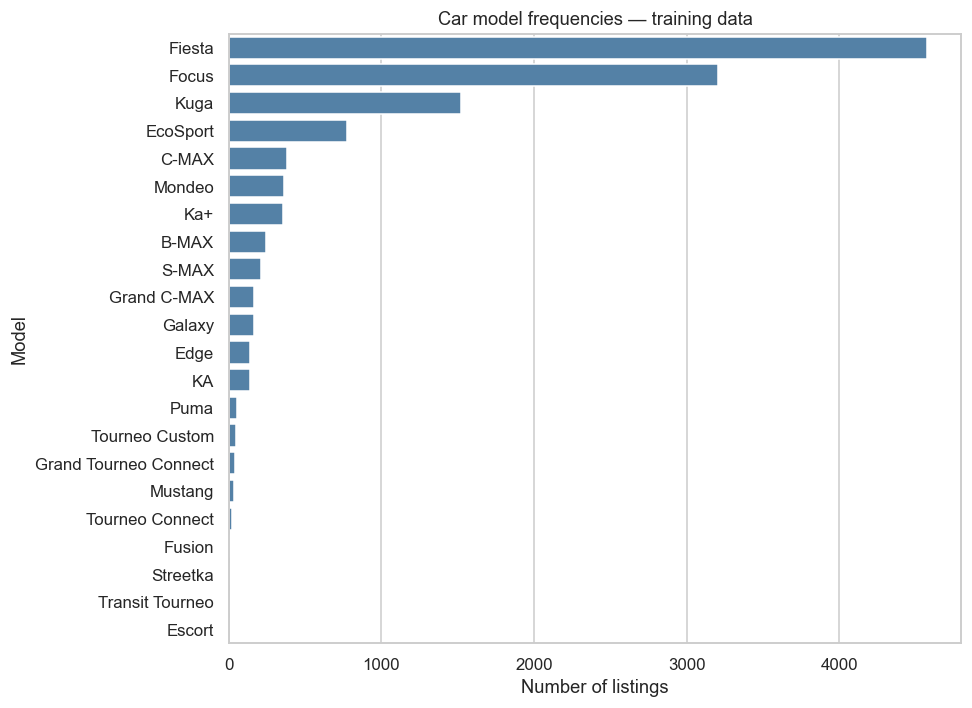

In [9]:
model_order = train_df["model"].value_counts().index
fig, ax = plt.subplots(figsize=(9, max(4, 0.3 * len(model_order))))
sns.countplot(data=train_df, y="model", order=model_order, color="steelblue", ax=ax)
ax.set(title="Car model frequencies — training data", xlabel="Number of listings", ylabel="Model")
fig.tight_layout()
plt.show()


### 10. Plot transmission and fuel frequencies

- Compare the number of training listings for each transmission and fuel type.
- Counts describe representation in the sample, not the effect of a category on price.


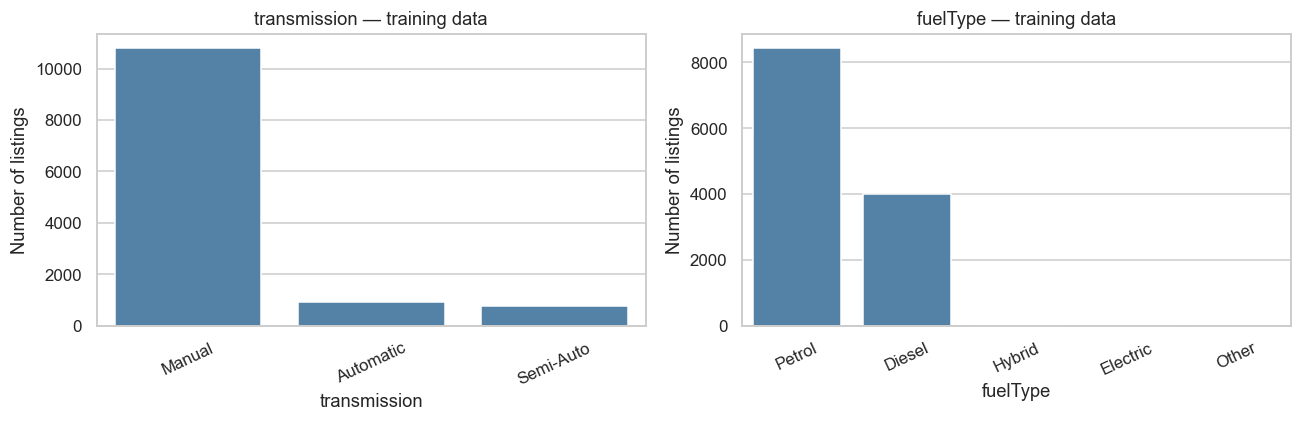

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["transmission", "fuelType"]):
    sns.countplot(data=train_df, x=column, order=train_df[column].value_counts().index,
                  color="steelblue", ax=ax)
    ax.set(title=f"{column} — training data", xlabel=column, ylabel="Number of listings")
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

### 11. Compare price distributions across categories

- Use box plots to show medians, spread, and unusual prices instead of relying only on group means.
- Group differences are descriptive and may also reflect model, year, mileage, and other factors; they do not establish causality.


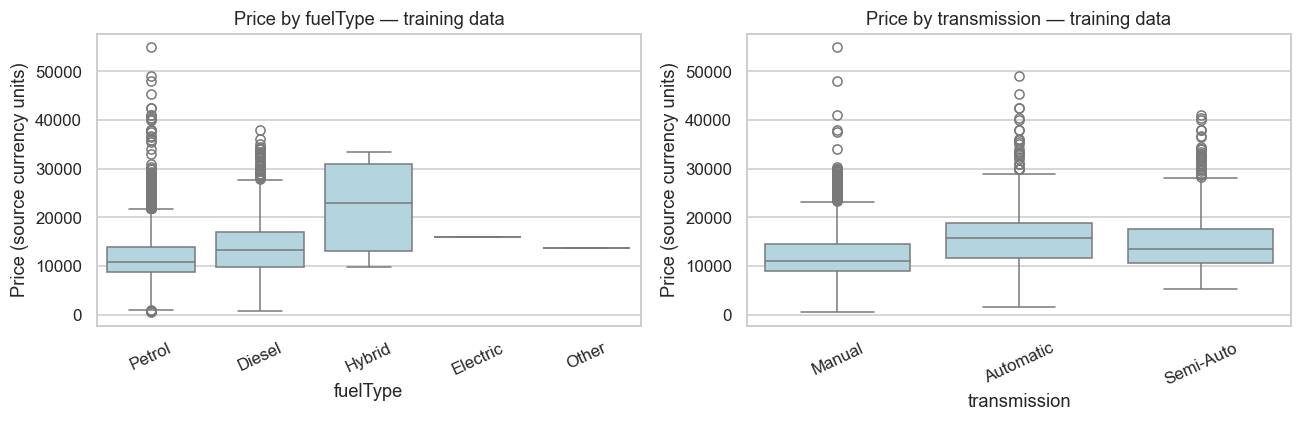

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["fuelType", "transmission"]):
    sns.boxplot(data=train_df, x=column, y="price", color="lightblue", ax=ax)
    ax.set(title=f"Price by {column} — training data", xlabel=column, ylabel="Price (source currency units)")
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

### 12. Examine numeric correlations

- Compute Pearson correlations only for genuinely numeric variables; arbitrary category codes are not meaningful numeric measurements.
- Use a diverging heatmap with limits −1 to +1 and show correlations with price separately.
- Pandas uses available pairs when values are missing; these associations guide inspection, not causal interpretation or automatic feature deletion.


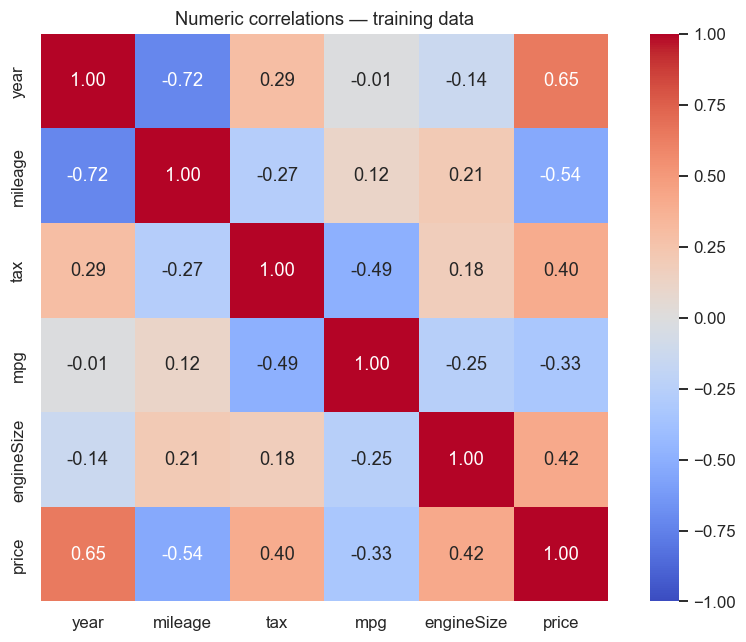

,Correlation with price
mileage,-0.536743
mpg,-0.330256
tax,0.401248
engineSize,0.416045
year,0.646045


In [12]:
numeric_correlation = train_df[numeric_features + [target_column]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(numeric_correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title("Numeric correlations — training data")
fig.tight_layout()
plt.show()
display(numeric_correlation["price"].drop("price").sort_values().to_frame("Correlation with price"))

### 13. Inspect year, mileage, and price

- Put predictors on the horizontal axis and price on the vertical axis.
- Show year and mileage separately to inspect the plausibility of a linear model; each plot is unadjusted for the other predictors.
- Use a fixed random sample of at most 3,000 training rows to keep plotting responsive.


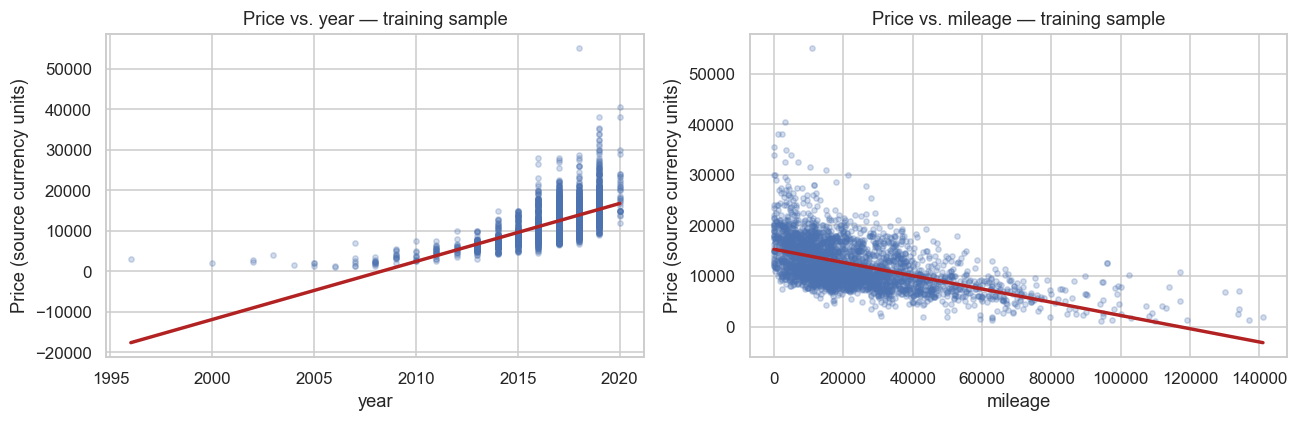

In [13]:
plot_df = train_df.sample(n=min(3000, len(train_df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["year", "mileage"]):
    sns.regplot(data=plot_df, x=column, y="price", ci=None,
                scatter_kws={"alpha": 0.25, "s": 12},
                line_kws={"color": "firebrick"}, ax=ax)
    ax.set(title=f"Price vs. {column} — training sample", ylabel="Price (source currency units)")
fig.tight_layout()
plt.show()

## Multiple linear regression and preprocessing

- The model predicts price as $\hat y = b_0 + \sum_{j=1}^{p} b_j z_j$, where $z_j$ are the transformed predictors.
- Numeric features are filled with training medians and standardized using training means and standard deviations.
- Nominal categories are filled with their training mode and one-hot encoded; manual/automatic and petrol/diesel have no natural numeric order.
- Drop one category per feature to define reference categories; unseen categories are encoded as all zeros, so their predictions should be treated cautiously.
- Scaling is not essential for ordinary least-squares predictions but makes numeric feature magnitudes comparable and is retained from the original workflow.
- Keep every preprocessing step inside the pipeline so cross-validation learns a fresh transformation from each training fold.


### 14. Build the preprocessing pipeline

- Process numeric and categorical columns separately using their names.
- Use `keep_empty_features=True` so a sparse fold does not silently change the expected feature set.
- Use `handle_unknown="ignore"` so a previously unseen category does not crash prediction; scikit-learn may warn when that occurs.
- Do not manually scale, encode, or impute the full dataset before cross-validation.


In [14]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
], remainder="drop", verbose_feature_names_out=True)

price_model = Pipeline([
    ("preprocess", preprocessor),
    ("regressor", LinearRegression())
])
print("Created preprocessing + linear regression pipeline.")

Created preprocessing + linear regression pipeline.


### 15. Cross-validate on the training set only

- Use five shuffled folds of the training set; keep the held-out test set out of cross-validation.
- Score R², MAE, and RMSE rather than calling a regression score classification accuracy.
- Scikit-learn returns negative error scores because its scoring convention is “higher is better”; reverse their signs for reporting.
- Report fold means and standard deviations; fold standard deviations describe variability and are not confidence intervals.
- Keep the baseline and model specification fixed before examining final test scores.


In [15]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {"R2": "r2", "MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error"}
cv_results = cross_validate(price_model, X_train, y_train, cv=cv,
                            scoring=scoring, n_jobs=1, error_score="raise")
cv_summary = pd.DataFrame({
    "Metric": ["R²", "MAE (currency units)", "RMSE (currency units)"],
    "Fold mean": [cv_results["test_R2"].mean(), -cv_results["test_MAE"].mean(),
                  -cv_results["test_RMSE"].mean()],
    "Fold standard deviation": [cv_results["test_R2"].std(ddof=1), cv_results["test_MAE"].std(ddof=1),
                                cv_results["test_RMSE"].std(ddof=1)]
})
display(cv_summary)

c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Metric,Fold mean,Fold standard deviation
0,R²,0.845776,0.010586
1,MAE (currency units),1365.753094,14.270286
2,RMSE (currency units),1860.698941,63.914612


### 16. Fit the final training model and baseline

- Fit the full pipeline on all training rows, after cross-validation.
- Fit a median-price baseline using training prices only; the median is a natural constant predictor when judging MAE.
- Generate test predictions without clipping negative values, since clipping would change the evaluated model.


In [16]:
price_model.fit(X_train, y_train)
test_predictions = price_model.predict(X_test)
baseline = DummyRegressor(strategy="median")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_predictions = baseline.predict(np.zeros((len(y_test), 1)))
print("Training complete.")
print("Negative regression test predictions:", int((test_predictions < 0).sum()))

Training complete.
Negative regression test predictions: 42


c:\Users\user\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### 17. Evaluate the untouched test set

- MAE is the mean absolute price error; MSE is the mean squared error; RMSE is its square root in price units.
- R² compares squared error against predicting the test-set mean; it can be negative and is not an accuracy percentage.
- Compare regression against the training-median baseline on the same observations.
- Report undefined R² as NaN if all test prices are identical; do not reuse old results from the original notebook.


In [17]:
def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(actual, predicted) if pd.Series(actual).nunique() > 1 else np.nan
    }

test_metrics = pd.DataFrame({
    "Linear regression": regression_metrics(y_test, test_predictions),
    "Training-median baseline": regression_metrics(y_test, baseline_predictions)
}).T
display(test_metrics)
print("MAE/RMSE: source currency units; MSE: squared currency units; R²: unitless.")

,MAE,MSE,RMSE,R²
Linear regression,1343.961765,3.257818e+06,1804.942564,0.854132
Training-median baseline,3595.805015,2.331986e+07,4829.063811,-0.044142


MAE/RMSE: source currency units; MSE: squared currency units; R²: unitless.


### 18. Review individual test errors

- Keep actual prices, predictions, and residuals together with the original row index.
- Define residual as actual minus predicted price: positive values indicate underprediction.
- Show a small preview and the five largest absolute errors to make model failures inspectable.


In [18]:
test_results = X_test.copy()
test_results["Actual price"] = y_test
test_results["Predicted price"] = test_predictions
test_results["Residual"] = y_test.to_numpy() - test_predictions
test_results["Absolute error"] = test_results["Residual"].abs()
display(test_results.head(10))
display(test_results.nlargest(5, "Absolute error"))

,year,mileage,tax,mpg,engineSize,model,transmission,fuelType,Actual price,Predicted price,Residual,Absolute error
1026,2017.0,50565.0,150.0,56.5,2.0,Galaxy,Manual,Diesel,14995.0,17115.587339,-2120.587339,2120.587339
16825,2005.0,87530.0,235.0,39.8,2.0,Focus,Manual,Petrol,2295.0,-907.102341,3202.102341,3202.102341
2848,2016.0,13820.0,200.0,41.5,2.0,Focus,Manual,Petrol,14950.0,15855.365816,-905.365816,905.365816
11444,2017.0,26181.0,145.0,41.5,2.0,Focus,Manual,Petrol,17890.0,16253.761742,1636.238258,1636.238258
9994,2018.0,26500.0,150.0,60.1,1.0,Focus,Manual,Petrol,11795.0,12935.149122,-1140.149122,1140.149122
10927,2015.0,33000.0,0.0,65.7,1.0,Fiesta,Manual,Petrol,8263.0,6920.394621,1342.605379,1342.605379
15294,2016.0,32737.0,0.0,65.7,1.0,Fiesta,Manual,Petrol,8000.0,8050.751248,-50.751248,50.751248
2301,2019.0,10465.0,145.0,37.7,2.0,Kuga,Manual,Diesel,20500.0,20108.878496,391.121504,391.121504
17739,2018.0,22000.0,150.0,65.7,1.0,Fiesta,Manual,Petrol,9999.0,10801.229655,-802.229655,802.229655
13810,2018.0,16299.0,145.0,54.3,1.0,EcoSport,Manual,Petrol,15000.0,12491.785316,2508.214684,2508.214684


,year,mileage,tax,mpg,engineSize,model,transmission,fuelType,Actual price,Predicted price,Residual,Absolute error
11782,2017.0,21575.0,145.0,20.9,5.0,Mustang,Manual,Petrol,49999.0,34576.836869,15422.163131,15422.163131
7660,2017.0,10057.0,235.0,36.7,2.3,Focus,Manual,Petrol,32000.0,18441.154540,13558.845460,13558.845460
13195,2019.0,11500.0,145.0,47.1,2.0,Mondeo,Automatic,Diesel,32000.0,18860.158265,13139.841735,13139.841735
2002,2018.0,13847.0,145.0,58.9,1.0,Focus,Manual,Petrol,25998.0,13805.128239,12192.871761,12192.871761
10836,2020.0,10.0,145.0,39.8,1.5,Focus,Automatic,Petrol,30999.0,20234.210347,10764.789653,10764.789653


### 19. Plot actual and predicted prices

- Perfect predictions would lie on the diagonal.
- Inspect systematic over- or underprediction, especially among expensive vehicles.
- Use all held-out observations in this diagnostic.


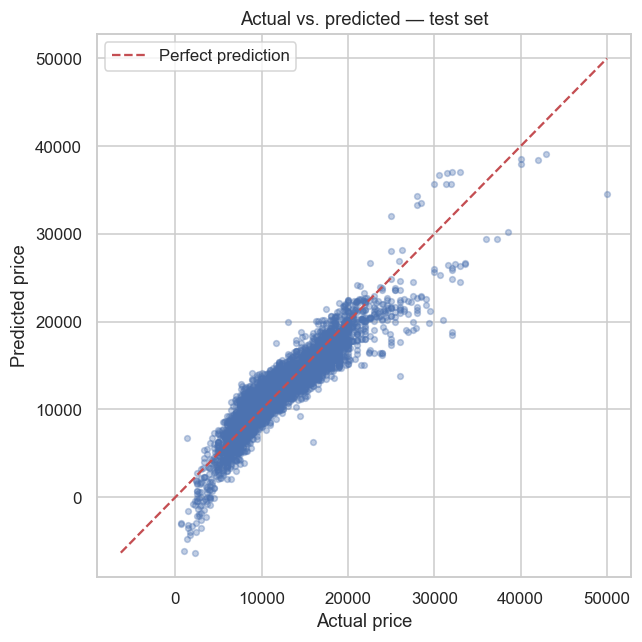

In [19]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_predictions, alpha=0.35, s=14)
low = min(y_test.min(), test_predictions.min())
high = max(y_test.max(), test_predictions.max())
ax.plot([low, high], [low, high], "r--", label="Perfect prediction")
ax.set(xlabel="Actual price", ylabel="Predicted price", title="Actual vs. predicted — test set")
ax.legend()
fig.tight_layout()
plt.show()

### 20. Inspect residual patterns

- A curved residual pattern suggests the mean relationship may not be adequately linear.
- A widening residual spread suggests errors may grow with predicted price.
- A Q–Q plot shows departures from a normal residual distribution; normality is not required to compute OLS predictions or MAE.
- Test residuals need not sum to zero; that property applies to training residuals for an intercept-containing OLS fit.


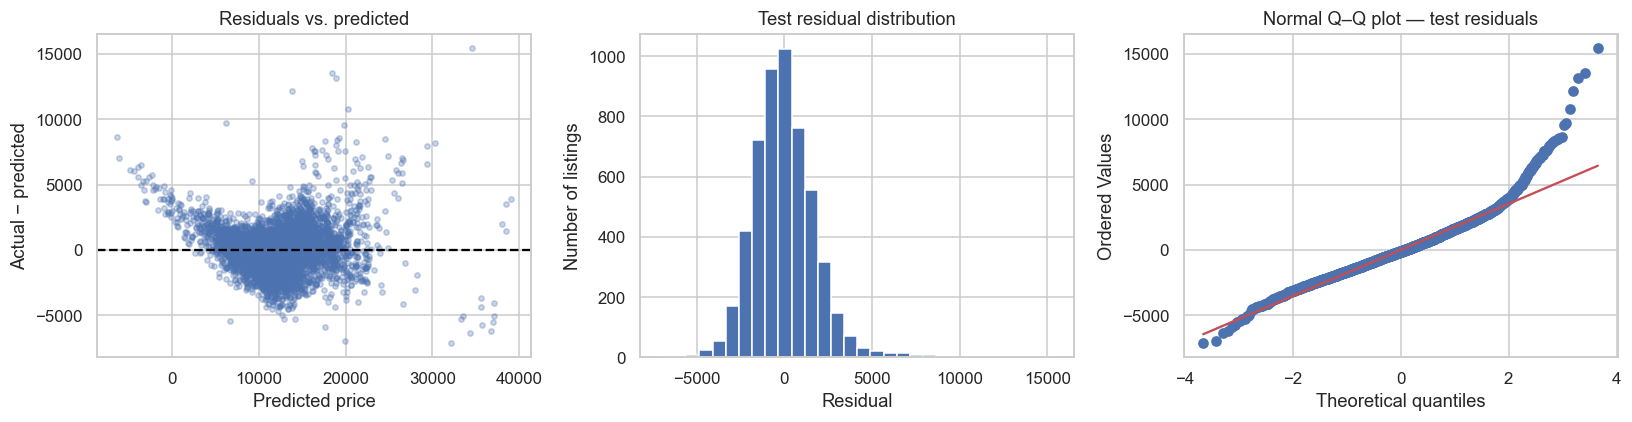

In [20]:
test_residuals = y_test.to_numpy() - test_predictions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(test_predictions, test_residuals, alpha=0.3, s=12)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(xlabel="Predicted price", ylabel="Actual − predicted", title="Residuals vs. predicted")
axes[1].hist(test_residuals, bins=30, edgecolor="white")
axes[1].set(xlabel="Residual", ylabel="Number of listings", title="Test residual distribution")
stats.probplot(test_residuals, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q–Q plot — test residuals")
fig.tight_layout()
plt.show()

### 21. Predict a new car using named features

- Replace the anonymous `f0`, `f1`, … inputs with the same descriptive columns used during training.
- Retain the original example values and explicitly supply a model, here `Fiesta`, because model is now included.
- Pass raw values through the fitted pipeline so all preprocessing is applied consistently.
- Flag unseen categories and numeric values outside the observed training ranges; a nonnegative point prediction still carries uncertainty and is not a guaranteed sale price.


In [21]:
new_car = pd.DataFrame([{
    "model": "Fiesta", "year": 2020, "transmission": "Automatic",
    "mileage": 1000, "fuelType": "Petrol", "tax": 150,
    "mpg": 57.7, "engineSize": 1.5
}])[feature_columns]

input_warnings = []
for column in categorical_features:
    if new_car.at[0, column] not in set(X_train[column].dropna()):
        input_warnings.append(f"Unseen {column}: {new_car.at[0, column]}")
for column in numeric_features:
    observed = X_train[column].dropna()
    value = new_car.at[0, column]
    if not observed.min() <= value <= observed.max():
        input_warnings.append(f"{column}={value} is outside the observed training range.")

new_prediction = float(price_model.predict(new_car)[0])
display(new_car)
print(f"Predicted advertised price: {new_prediction:,.2f} (source currency units)")
for message in input_warnings:
    print("Caution:", message)
if new_prediction < 0:
    print("Caution: the model produced an implausible negative price; do not use this estimate.")

,year,mileage,tax,mpg,engineSize,model,transmission,fuelType
0,2020,1000,150,57.7,1.5,Fiesta,Automatic,Petrol


Predicted advertised price: 16,953.93 (source currency units)


## Interpretation and next steps

- Lower MAE and RMSE indicate smaller errors; compare them with typical training prices and the median baseline, rather than calling R² “accuracy.”
- The model estimates advertised price for Ford listings resembling the training data; it does not directly estimate realized transaction prices or prices of other manufacturers.
- A random split does not measure performance in a future market; use listing dates and a chronological evaluation when those data become available.
- Exact-duplicate removal cannot identify multiple different listings of the same vehicle without a vehicle or listing identifier.
- Rare models, unfamiliar categories, unusual specifications, and combinations absent from training can produce unreliable predictions, even when each numeric value is within its individual training range.
- A year of 2060 is treated as invalid and made missing, then imputed within the training pipeline; this does not recover the true year, and the source record should be corrected if authoritative information becomes available.
- Large or patterned residuals motivate future comparisons with transformed targets, interactions, regularized regression, or nonlinear models; compare candidates using training-only cross-validation.
- Once test diagnostics are used to choose further model changes, that test set becomes development data; use fresh held-out data for a new unbiased final evaluation.
- No prediction intervals are supplied, and feature associations do not establish causal effects.
